In [1]:
import sys, subprocess, os, warnings, urllib.request, zipfile
warnings.filterwarnings("ignore")
try:
    import xgboost
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "xgboost"])
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display
from scipy import stats
from sklearn.model_selection import train_test_split, GridSearchCV, KFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
from xgboost import XGBRegressor

sns.set_theme(style="whitegrid")
RS = 42
os.makedirs("figures", exist_ok=True); os.makedirs("outputs", exist_ok=True)


## Cell 1: Load data (auto-download, or upload your Kaggle file)
Downloads `insurance.csv` automatically (or asks you to upload your Kaggle copy) and shows size, types and statistics.

In [2]:
URL = "https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-datasets/master/insurance.csv"
PATH = "insurance.csv"
if not os.path.exists(PATH):
    try:
        urllib.request.urlretrieve(URL, PATH)
    except Exception as e:
        print("Download failed:", e)
        if IN_COLAB:
            from google.colab import files
            print("Upload insurance.csv (from kaggle.com/datasets/mirichoi0218/insurance)")
            PATH = list(files.upload().keys())[0]
df = pd.read_csv(PATH)
print("Shape:", df.shape); display(df.head()); display(df.describe().T.round(2))


Shape: (1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


,count,mean,std,min,25%,50%,75%,max
age,1338.0,39.21,14.05,18.00,27.00,39.00,51.00,64.00
bmi,1338.0,30.66,6.10,15.96,26.30,30.40,34.69,53.13
children,1338.0,1.09,1.21,0.00,0.00,1.00,2.00,5.00
charges,1338.0,13270.42,12110.01,1121.87,4740.29,9382.03,16639.91,63770.43


## Cell 2: EDA
Missing values, duplicates, outliers (IQR), distributions, and relationships with the target.

Missing values: 0 | Duplicate rows: 1


,feature,IQR outliers,skewness
0,age,0,0.05
1,bmi,9,0.28
2,children,0,0.94
3,charges,139,1.52


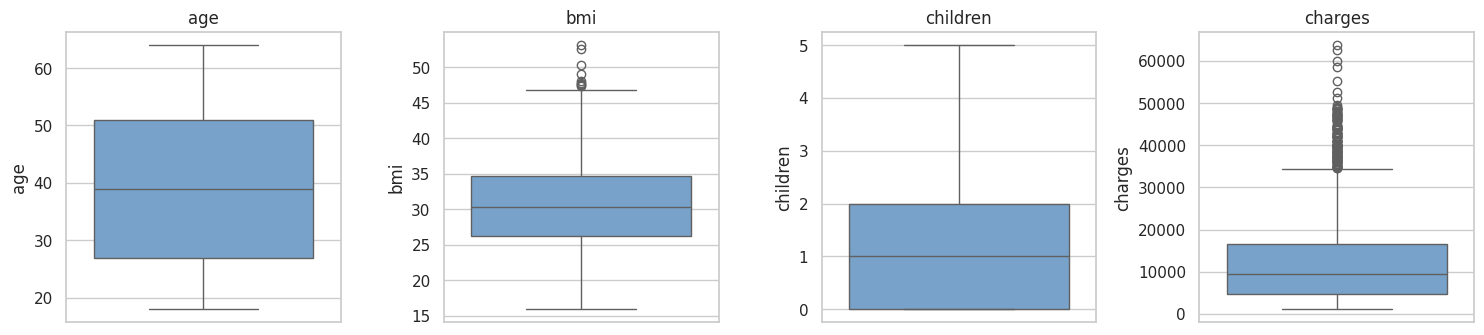

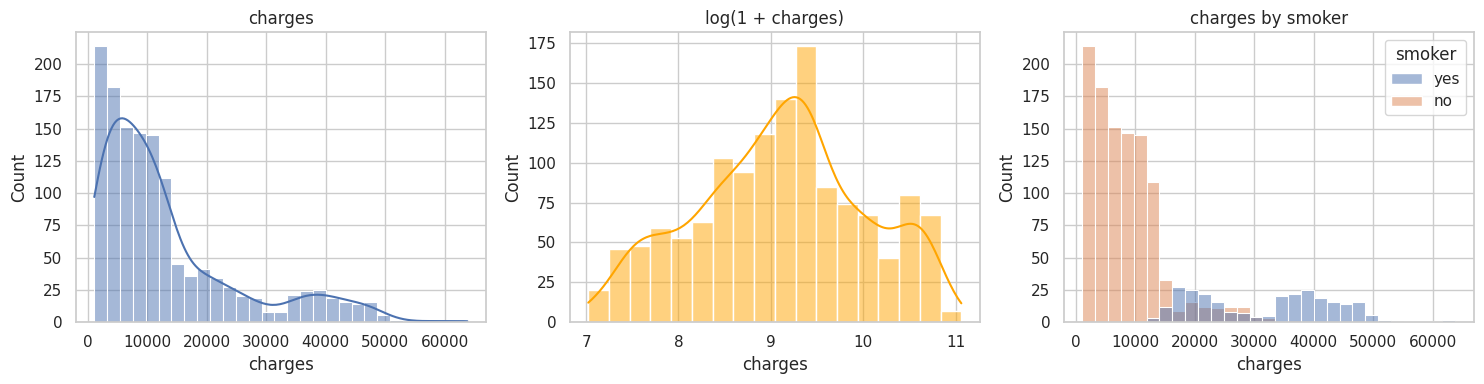

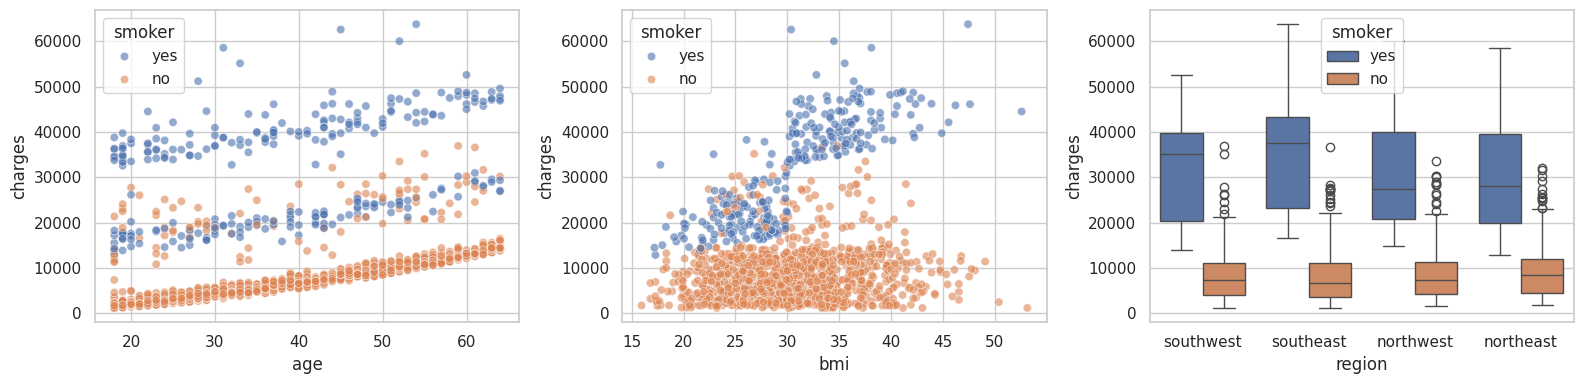

,count,mean,median
smoker,,,
no,1063,8441.0,7346.0
yes,274,32050.0,34456.0


In [3]:
print("Missing values:", df.isna().sum().sum(), "| Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)

rows_o = []
for c in ["age", "bmi", "children", "charges"]:
    q1, q3 = df[c].quantile([.25, .75]); i = q3 - q1
    rows_o.append([c, int(((df[c] < q1 - 1.5*i) | (df[c] > q3 + 1.5*i)).sum()), round(df[c].skew(), 2)])
display(pd.DataFrame(rows_o, columns=["feature", "IQR outliers", "skewness"]))

fig, ax = plt.subplots(1, 4, figsize=(15, 3.5))
for a, c in zip(ax, ["age", "bmi", "children", "charges"]):
    sns.boxplot(y=df[c], ax=a, color="#6BA3D6"); a.set_title(c)
plt.tight_layout(); plt.savefig("figures/boxplots.png", dpi=150); plt.show()

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(df.charges, kde=True, ax=ax[0]); ax[0].set_title("charges")
sns.histplot(np.log1p(df.charges), kde=True, ax=ax[1], color="orange"); ax[1].set_title("log(1 + charges)")
sns.histplot(data=df, x="charges", hue="smoker", ax=ax[2]); ax[2].set_title("charges by smoker")
plt.tight_layout(); plt.savefig("figures/distributions.png", dpi=150); plt.show()

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.scatterplot(data=df, x="age", y="charges", hue="smoker", alpha=.6, ax=ax[0])
sns.scatterplot(data=df, x="bmi", y="charges", hue="smoker", alpha=.6, ax=ax[1])
sns.boxplot(data=df, x="region", y="charges", hue="smoker", ax=ax[2])
plt.tight_layout(); plt.savefig("figures/relationships.png", dpi=150); plt.show()
display(df.groupby("smoker").charges.agg(["count", "mean", "median"]).round(0))


## Cell 3: Encoding, correlation, 70/30 split
One-hot encoding, correlation heatmap and the 70/30 train/test split.

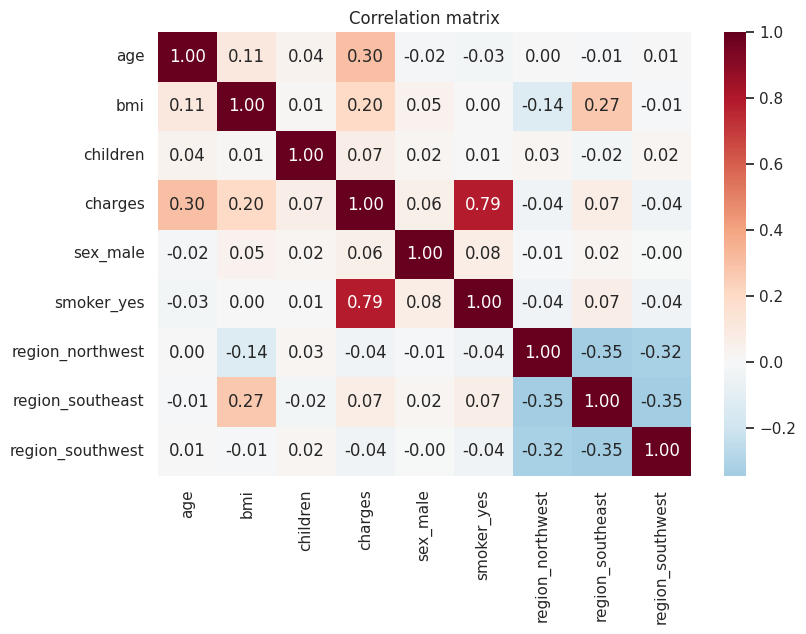

Train: (935, 8) | Test: (402, 8)


In [4]:
d = pd.get_dummies(df, columns=["sex", "smoker", "region"], drop_first=True, dtype=int)
plt.figure(figsize=(8.5, 6.5)); sns.heatmap(d.corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Correlation matrix"); plt.tight_layout(); plt.savefig("figures/correlation.png", dpi=150); plt.show()
X, y = d.drop(columns="charges"), d["charges"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=RS)
print("Train:", X_train.shape, "| Test:", X_test.shape)


## Cell 4: Baseline models
Linear Regression, Decision Tree and KNN, evaluated with MAE, RMSE, R² and 5-fold CV.

In [5]:
kf = KFold(5, shuffle=True, random_state=RS)
rmse = lambda a, b: np.sqrt(mean_squared_error(a, b))
rows, fitted = [], {}
def evaluate(name, stage, m):
    p = m.predict(X_test)
    cv = -cross_val_score(m, X_train, y_train, cv=kf, scoring="neg_root_mean_squared_error")
    rows.append(dict(Model=name, Stage=stage, Train_R2=r2_score(y_train, m.predict(X_train)),
        Test_MAE=mean_absolute_error(y_test, p), Test_RMSE=rmse(y_test, p), Test_R2=r2_score(y_test, p),
        CV_RMSE=cv.mean(), CV_RMSE_std=cv.std()))
    fitted[(name, stage)] = m
base = {"Linear Regression": Pipeline([("s", StandardScaler()), ("m", LinearRegression())]),
        "Decision Tree": DecisionTreeRegressor(random_state=RS),
        "KNN (k=5)": Pipeline([("s", StandardScaler()), ("m", KNeighborsRegressor(5))])}
for n, m in base.items(): evaluate(n, "Baseline", m.fit(X_train, y_train))
display(pd.DataFrame(rows).round(3))


,Model,Stage,Train_R2,Test_MAE,Test_RMSE,Test_R2,CV_RMSE,CV_RMSE_std
0,Linear Regression,Baseline,0.736,4181.816,6240.206,0.772,6023.709,375.139
1,Decision Tree,Baseline,1.000,2887.016,6204.084,0.775,6513.523,390.405
2,KNN (k=5),Baseline,0.855,3549.083,5731.237,0.808,5500.908,409.973


## Cell 5: Advanced models: GridSearchCV + 5-fold CV
GridSearchCV tuning of Decision Tree, KNN, Random Forest, Gradient Boosting and XGBoost, with cross-validation (slowest cell, about 1 minute).

Decision Tree      CV RMSE =    4556  {'max_depth': 4, 'min_samples_leaf': 10}
KNN                CV RMSE =    5427  {'m__n_neighbors': 5, 'm__weights': 'distance'}
Random Forest      CV RMSE =    4407  {'max_depth': 5, 'min_samples_leaf': 10, 'n_estimators': 300}
Gradient Boosting  CV RMSE =    4437  {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 100, 'subsample': 0.8}
XGBoost            CV RMSE =    4386  {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 100, 'subsample': 1.0}


,Model,Stage,Train_R2,Test_MAE,Test_RMSE,Test_R2,CV_RMSE,CV_RMSE_std
2,KNN (k=5),Baseline,0.855,3549.083,5731.237,0.808,5500.908,409.973
1,Decision Tree,Baseline,1.000,2887.016,6204.084,0.775,6513.523,390.405
0,Linear Regression,Baseline,0.736,4181.816,6240.206,0.772,6023.709,375.139
7,XGBoost,Tuned,0.879,2544.260,4602.363,0.876,4386.303,824.854
5,Random Forest,Tuned,0.875,2538.885,4607.033,0.876,4406.827,785.156
6,Gradient Boosting,Tuned,0.883,2575.870,4660.828,0.873,4436.780,749.112
3,Decision Tree,Tuned,0.863,2719.555,4779.034,0.867,4555.918,743.888
4,KNN,Tuned,1.000,3423.935,5743.064,0.807,5426.822,441.297


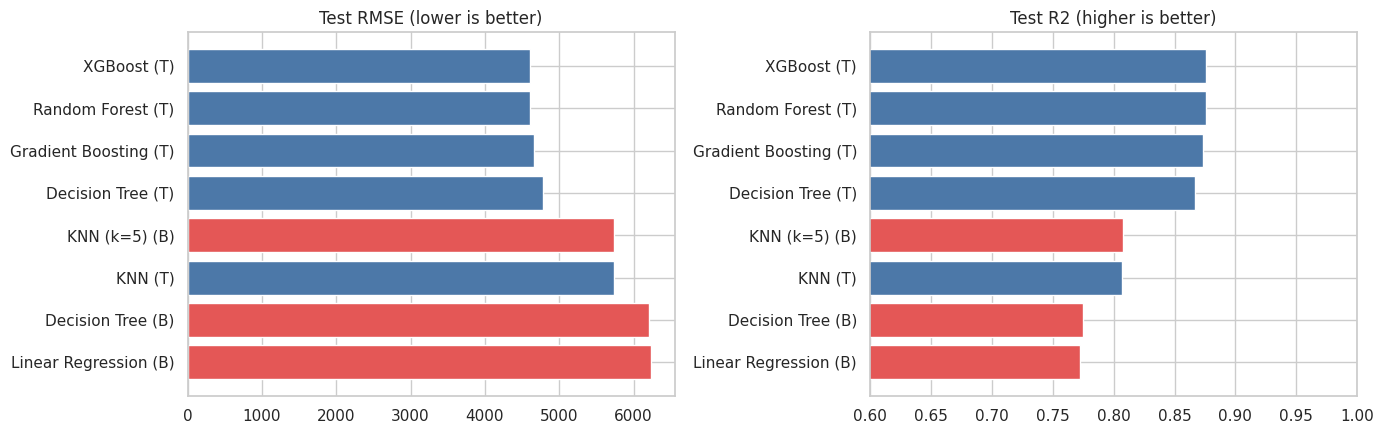

In [6]:
grids = {
 "Decision Tree": (DecisionTreeRegressor(random_state=RS), {"max_depth": [3,4,5,6,8,None], "min_samples_leaf": [1,5,10,20]}),
 "KNN": (Pipeline([("s", StandardScaler()), ("m", KNeighborsRegressor())]), {"m__n_neighbors": [3,5,7,9,11,15,21], "m__weights": ["uniform","distance"]}),
 "Random Forest": (RandomForestRegressor(random_state=RS, n_jobs=-1), {"n_estimators": [100,300], "max_depth": [3,5,8,None], "min_samples_leaf": [1,3,5,10]}),
 "Gradient Boosting": (GradientBoostingRegressor(random_state=RS), {"n_estimators": [100,200,300], "learning_rate": [0.01,0.05,0.1], "max_depth": [2,3,4], "subsample": [0.8,1.0]}),
 "XGBoost": (XGBRegressor(random_state=RS, n_jobs=-1), {"n_estimators": [100,200,300], "learning_rate": [0.01,0.05,0.1], "max_depth": [2,3,4], "subsample": [0.8,1.0]}),
}
best = {}
for n, (est, g) in grids.items():
    gs = GridSearchCV(est, g, cv=kf, scoring="neg_root_mean_squared_error", n_jobs=-1).fit(X_train, y_train)
    best[n] = gs.best_params_; print(f"{n:18s} CV RMSE = {-gs.best_score_:7.0f}  {gs.best_params_}")
    evaluate(n, "Tuned", gs.best_estimator_)
res = pd.DataFrame(rows).round(3)
res.to_csv("outputs/model_comparison.csv", index=False)
display(res.sort_values(["Stage", "Test_RMSE"]))

o = res.sort_values("Test_RMSE")
lab = o.Model + " (" + o.Stage.str[0] + ")"
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
cols = ["#E45756" if s == "Baseline" else "#4C78A8" for s in o.Stage]
ax[0].barh(lab, o.Test_RMSE, color=cols); ax[0].invert_yaxis(); ax[0].set_title("Test RMSE (lower is better)")
ax[1].barh(lab, o.Test_R2, color=cols); ax[1].invert_yaxis(); ax[1].set_xlim(0.6, 1); ax[1].set_title("Test R2 (higher is better)")
plt.tight_layout(); plt.savefig("figures/model_comparison.png", dpi=150); plt.show()


## Cell 6: Final model, residual analysis, feature importance
Picks the final model by CV RMSE, then residual analysis and feature importance.

FINAL MODEL (lowest CV RMSE): XGBoost {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 100, 'subsample': 1.0}


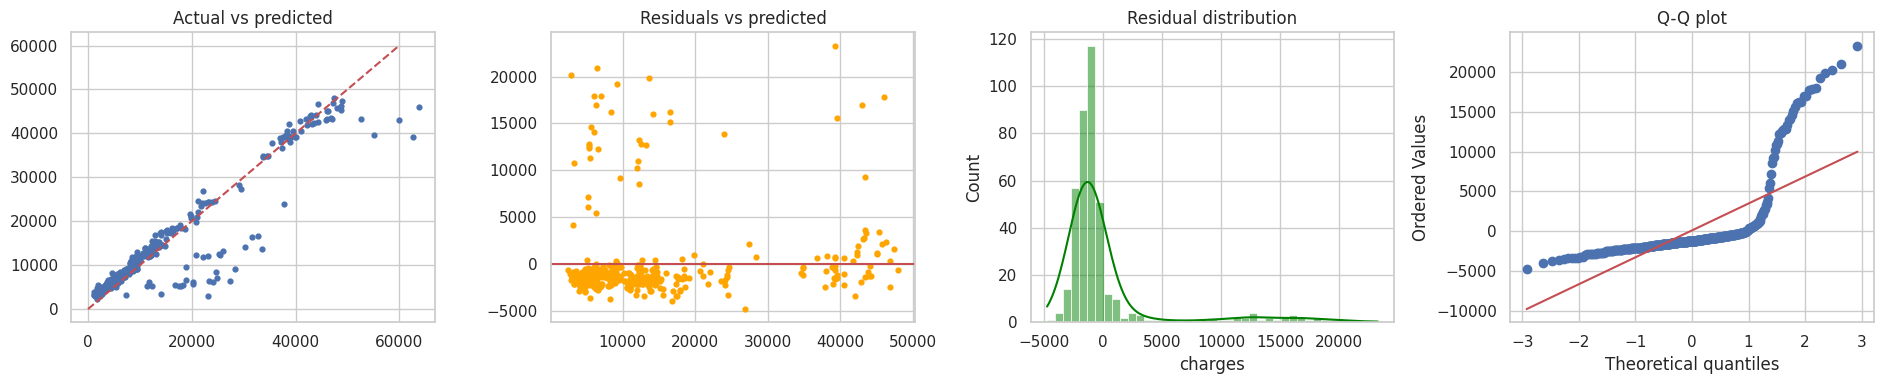

Residual mean = 114, std = 4607, skew = 3.03


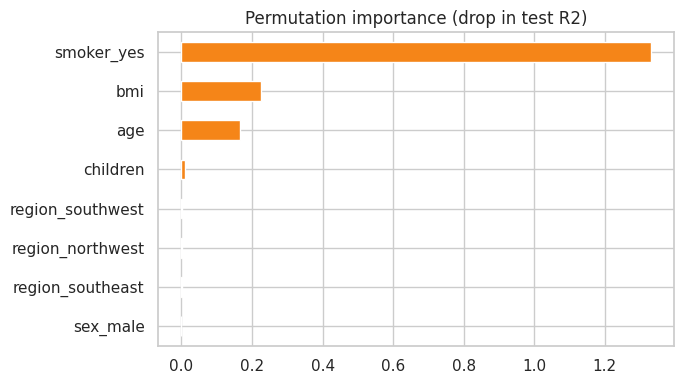

,Model,Stage,Train_R2,Test_MAE,Test_RMSE,Test_R2,CV_RMSE,CV_RMSE_std
7,XGBoost,Tuned,0.879,2544.26,4602.363,0.876,4386.303,824.854


In [7]:
tuned = res[res.Stage == "Tuned"].sort_values("CV_RMSE")
name = tuned.iloc[0].Model; model = fitted[(name, "Tuned")]
print("FINAL MODEL (lowest CV RMSE):", name, best[name])
pred = model.predict(X_test); resid = y_test - pred
fig, ax = plt.subplots(1, 4, figsize=(19, 4))
ax[0].scatter(y_test, pred, s=12); ax[0].plot([0, 60000], [0, 60000], "r--"); ax[0].set_title("Actual vs predicted")
ax[1].scatter(pred, resid, s=12, color="orange"); ax[1].axhline(0, color="r"); ax[1].set_title("Residuals vs predicted")
sns.histplot(resid, kde=True, ax=ax[2], color="green"); ax[2].set_title("Residual distribution")
stats.probplot(resid, dist="norm", plot=ax[3]); ax[3].set_title("Q-Q plot")
plt.tight_layout(); plt.savefig("figures/residuals.png", dpi=150); plt.show()
print(f"Residual mean = {resid.mean():.0f}, std = {resid.std():.0f}, skew = {resid.skew():.2f}")

pi = permutation_importance(model, X_test, y_test, n_repeats=30, random_state=RS, scoring="r2")
imp = pd.Series(pi.importances_mean, index=X.columns).sort_values()
plt.figure(figsize=(7, 4)); imp.plot.barh(color="#F58518", title="Permutation importance (drop in test R2)")
plt.tight_layout(); plt.savefig("figures/feature_importance.png", dpi=150); plt.show()
display(res[(res.Model == name) & (res.Stage == "Tuned")])


## Cell 7: Save everything and download (Colab)
Zips the figures and tables and downloads `CA4_results.zip` (download works in Colab).

In [ ]:
with zipfile.ZipFile("CA4_results.zip", "w") as z:
    for folder in ["figures", "outputs"]:
        for f in os.listdir(folder): z.write(os.path.join(folder, f))
print("Saved figures + tables to CA4_results.zip")
if IN_COLAB:
    from google.colab import files
    files.download("CA4_results.zip")


Saved figures + tables to CA4_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>